# Riesgo de rotura priorizado por margen y cohortes
Responsable: Persona 3 · Entrega 1 · Requiere `uv run novaretail all` antes de ejecutar.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd() / "src", Path.cwd().parent / "src"]:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import pandas as pd
import matplotlib.pyplot as plt
from novaretail import cohorts, stock
from novaretail.config import CLEAN, FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)
inventory = pd.read_parquet(CLEAN / "inventory_weekly.parquet")
sales = pd.read_parquet(CLEAN / "sales.parquet")
products = pd.read_parquet(CLEAN / "products.parquet")
stores = pd.read_parquet(CLEAN / "stores.parquet")
orders = pd.read_parquet(CLEAN / "orders.parquet")
customers = pd.read_parquet(CLEAN / "customers.parquet")

## 1. Riesgo de rotura de stock y margen en riesgo

In [2]:
risk = stock.stockout_risk(inventory, sales, products)
risk = risk.merge(stores[["store_id", "store_name", "region", "format"]], on="store_id", how="left")

print(f"Margen total en riesgo semanal: {risk['margin_at_risk_eur'].sum():,.2f} €")
print(f"Margen en riesgo en combinaciones a reponer esta semana: {risk.loc[risk['reorder_now'], 'margin_at_risk_eur'].sum():,.2f} €")
print(f"Combinaciones a reponer esta semana: {risk['reorder_now'].sum()} de {len(risk)}")

region_summary = (
    risk.groupby("region", as_index=False)
    .agg(combinaciones=("product_id", "count"), a_reponer=("reorder_now", "sum"),
         unidades_a_pedir=("recommended_order_units", "sum"), margen_en_riesgo_eur=("margin_at_risk_eur", "sum"))
    .sort_values("margen_en_riesgo_eur", ascending=False)
)
display(region_summary)
display(risk.head(15))

Margen total en riesgo semanal: 23,931.92 €
Margen en riesgo en combinaciones a reponer esta semana: 2,846.94 €
Combinaciones a reponer esta semana: 38 de 5231


,region,combinaciones,a_reponer,unidades_a_pedir,margen_en_riesgo_eur
3,Sur,1456,17,119,7577.48
0,Centro,1354,6,49,5964.36
1,Este,1147,4,40,5201.65
2,Norte,1274,11,68,5188.43


,store_id,product_id,product_name,category,week,on_hand_units,on_order_units,lead_time_days,lead_time_weeks,expected_weekly_demand,coverage_weeks,stockout_prob,unit_margin_eur,demand_lead_time_units,margin_at_risk_eur,reorder_now,recommended_order_units,store_name,region,format
0,S017,P0070,Camisa Sierra Lite,Moda,2026-10-26,2,4,21,3.00,6.068322,0.99,0.6794,23.12,18.20,285.88,True,25,NovaRetail Sevilla 07,Sur,estandar
1,S007,P0380,Chaqueta Kairo Eco,Moda,2026-10-26,5,4,23,3.29,3.475686,2.59,0.5528,41.25,11.44,260.87,True,10,NovaRetail Bilbao 07,Norte,estandar
2,S015,P0379,Sudadera Novatek Max,Moda,2026-10-26,24,29,23,3.29,14.701023,3.61,0.4497,11.51,48.37,250.37,False,0,NovaRetail Málaga 05,Sur,estandar
3,S030,P0227,Pantalon Marea Plus,Moda,2026-10-26,17,0,24,3.43,5.319495,3.20,0.5207,24.86,18.25,236.24,True,12,NovaRetail Barcelona 10,Este,estandar
4,S022,P0180,Camiseta Zentro Plus,Moda,2026-10-26,9,10,28,4.00,4.514154,4.21,0.4839,25.73,18.06,224.86,False,0,NovaRetail Valencia 02,Este,estandar
5,S011,P0313,Cargador Marea Pro,Electronica,2026-10-26,9,12,21,3.00,4.436445,4.73,0.3332,45.62,13.31,202.32,False,0,NovaRetail Sevilla 01,Sur,flagship
6,S039,P0202,Muneca Marea Eco,Juguetes,2026-10-26,11,21,18,2.57,9.233175,3.47,0.3974,19.51,23.73,183.99,False,0,NovaRetail Valladolid 09,Centro,express
7,S014,P0355,Teclado Novatek,Electronica,2026-10-26,12,0,16,2.29,4.514154,2.66,0.4626,37.22,10.34,178.03,False,0,NovaRetail Sevilla 04,Sur,outlet
8,S036,P0389,Auriculares Novatek Plus,Electronica,2026-10-26,3,6,18,2.57,3.574588,2.52,0.5046,37.55,9.19,174.13,True,8,NovaRetail Valladolid 06,Centro,estandar
9,S019,P0073,Zapatillas Kairo Mini,Moda,2026-10-26,9,8,22,3.14,4.443510,3.83,0.4471,26.66,13.95,166.28,False,0,NovaRetail Granada 09,Sur,estandar


## 2. Recomendación táctica: dónde reponer esta semana

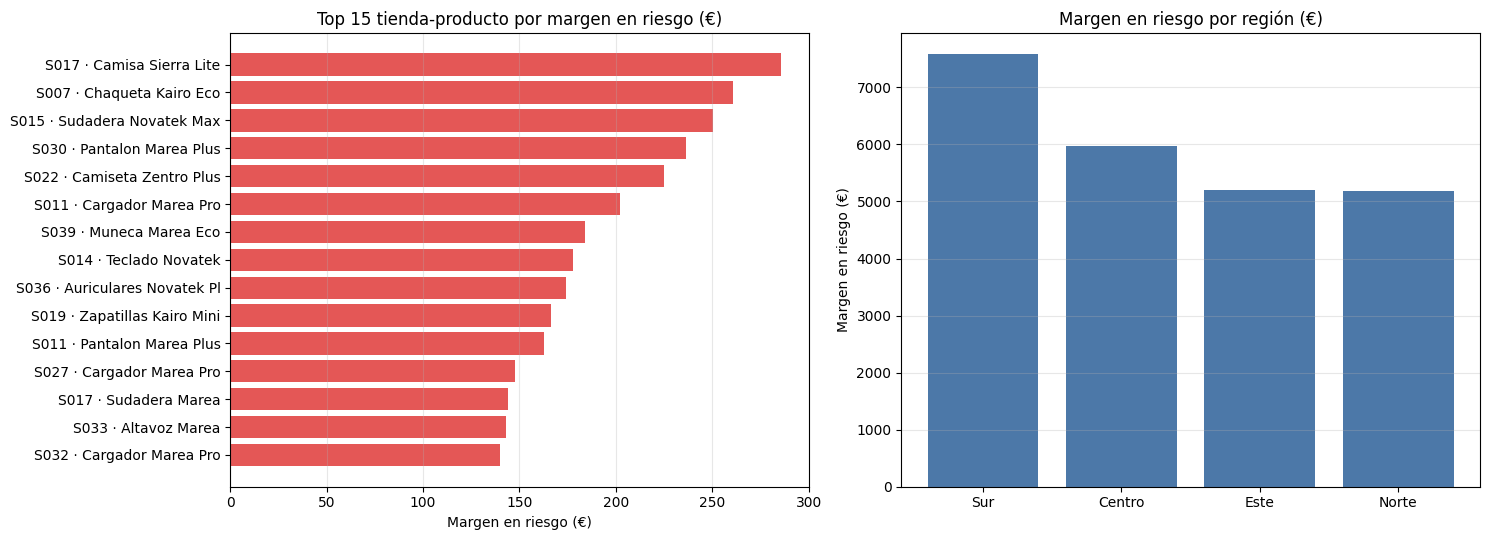

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top15 = risk.head(15).copy()
top15["label"] = top15["store_id"] + " · " + top15["product_name"].str.slice(0, 22)
top15 = top15.iloc[::-1]
axes[0].barh(top15["label"], top15["margin_at_risk_eur"], color="#E45756")
axes[0].set_title("Top 15 tienda-producto por margen en riesgo (€)")
axes[0].set_xlabel("Margen en riesgo (€)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].bar(region_summary["region"], region_summary["margen_en_riesgo_eur"], color="#4C78A8")
axes[1].set_title("Margen en riesgo por región (€)")
axes[1].set_ylabel("Margen en riesgo (€)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "stock_top_margen_riesgo.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Matriz de cohortes por canal de adquisición

month_offset,1,2,3,4,5,6,media_M1_M6
acquisition_channel,,,,,,,
referido,25.64,23.04,22.63,19.50,19.63,16.88,21.22
app,25.53,25.57,21.62,19.38,17.42,16.79,21.05
marketplace,26.29,23.25,20.41,19.64,17.95,17.10,20.77
tienda,25.67,23.92,21.78,19.29,16.77,15.33,20.46
web,25.49,22.85,20.87,18.82,17.63,16.25,20.32
redes_sociales,24.07,23.30,20.57,16.77,16.42,15.12,19.38


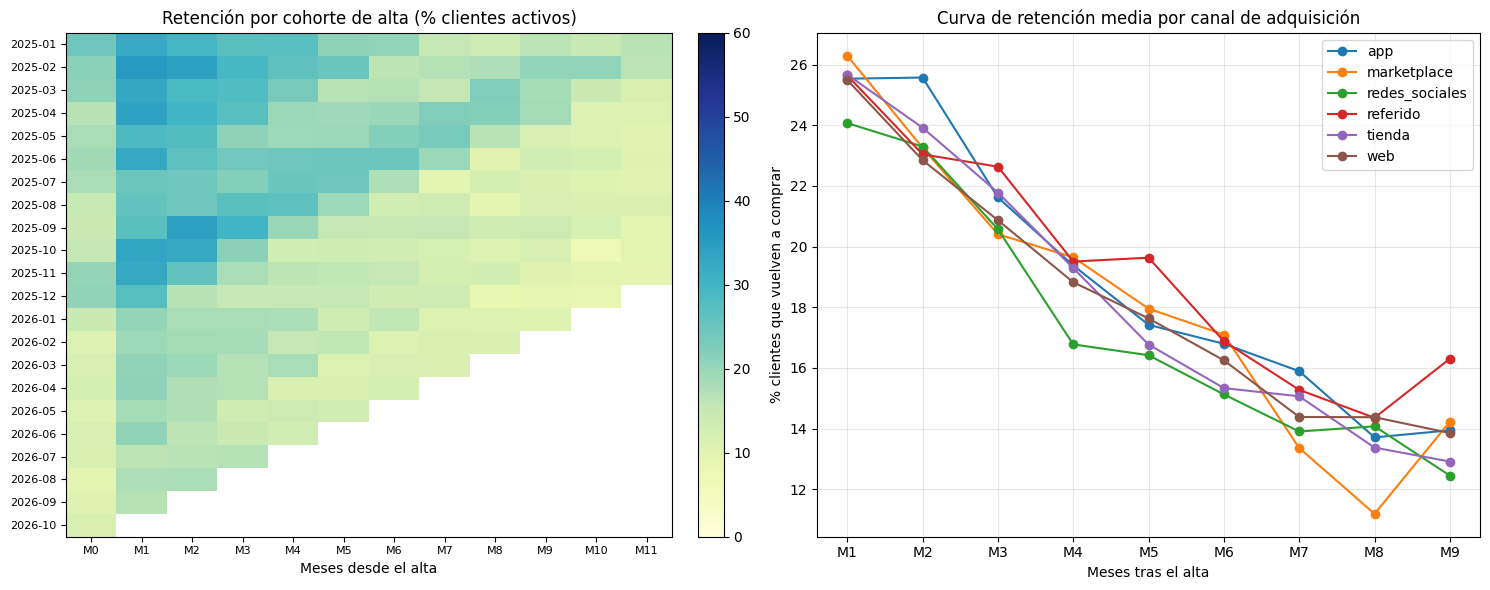

In [4]:
ret_global = cohorts.retention_matrix(orders, customers, by=None)
ret_by_ch = cohorts.retention_matrix(orders, customers, by="acquisition_channel")

cols_1_6 = [c for c in [1, 2, 3, 4, 5, 6] if c in ret_by_ch.columns]
ch_retention_summary = ret_by_ch[cols_1_6].groupby(level=0).mean().round(2)
ch_retention_summary["media_M1_M6"] = ch_retention_summary.mean(axis=1).round(2)
display(ch_retention_summary.sort_values("media_M1_M6", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
mat_plot = ret_global.iloc[:, :12]
im = axes[0].imshow(mat_plot.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=60)
axes[0].set_yticks(range(len(mat_plot.index)))
axes[0].set_yticklabels(mat_plot.index, fontsize=8)
axes[0].set_xticks(range(len(mat_plot.columns)))
axes[0].set_xticklabels([f"M{c}" for c in mat_plot.columns], fontsize=8)
axes[0].set_title("Retención por cohorte de alta (% clientes activos)")
axes[0].set_xlabel("Meses desde el alta")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

mean_curves = ret_by_ch.iloc[:, 1:10].groupby(level=0).mean()
for ch in mean_curves.index:
    axes[1].plot([f"M{c}" for c in mean_curves.columns], mean_curves.loc[ch], marker="o", label=ch)
axes[1].set_title("Curva de retención media por canal de adquisición")
axes[1].set_ylabel("% clientes que vuelven a comprar")
axes[1].set_xlabel("Meses tras el alta")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "cohortes_retencion_canal.png", dpi=200, bbox_inches="tight")
plt.show()